### In this notebook I tried a different approach with combining the datasets and did some EDA with the whole set

In [31]:
# IMPORTS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score

In [32]:
# Combining the datasets together with a new column for run_id and road_id

dfA1 = pd.read_csv("../dataset/cleaned/Iisingintie0.csv")
dfA2 = pd.read_csv("../dataset/cleaned/Iisingintie1.csv")
dfA3 = pd.read_csv("../dataset/cleaned/Iisingintie2.csv")

dfB1 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie0.csv")
dfB2 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie1.csv")
dfB3 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie2.csv")
dfB4 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie3.csv")

dfC1 = pd.read_csv("../dataset/cleaned/Kaittiaisentie0.csv")


runs = {
    "A1": (dfA1, "A"), "A2": (dfA2, "A"), "A3": (dfA3, "A"),
    "B1": (dfB1, "B"), "B2": (dfB2, "B"), "B3": (dfB3, "B"), "B4": (dfB4, "B"),
    "C1": (dfC1, "C"),
}

df = pd.concat(
    [d.assign(run_id=rid, road_id=road) for rid, (d, road) in runs.items()],
    ignore_index=True,
)

df["AccZ_max"] = df["AccZ"].max()

In [33]:
df

,Timer(ms),Loc(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),AccX,AccY,AccZ,GyrX,GyrY,GyrZ,RBCSV_80(cf),Speed_kmh,Frostbumps,run_id,road_id,AccZ_max
0,45493158.5,3850.503,106.794,1.1747,-3.0780,141.0204,1.53481,0.05712,9.58495,0.03196,0.00072,-0.00300,0.16845,62.1936,0,A1,A,24.57569
1,45493161.0,3850.546,106.794,1.2245,-3.0428,141.1350,1.51066,-0.04196,10.50449,0.02201,0.00598,-0.01390,0.16846,62.2044,0,A1,A,24.57569
2,45493163.5,3850.589,106.794,1.2281,-3.0428,141.1349,1.15831,0.37071,10.76888,0.01993,0.00065,-0.00562,0.16846,62.2116,0,A1,A,24.57569
3,45493166.0,3850.633,106.794,1.2330,-3.0430,141.1341,1.03301,0.31102,11.42271,0.02887,-0.00077,-0.01012,0.16845,62.2224,0,A1,A,24.57569
4,45493168.5,3850.676,106.794,1.2363,-3.0431,141.1329,0.99574,-0.37334,11.76243,0.01783,0.00007,-0.01306,0.16843,62.2332,0,A1,A,24.57569
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
396931,48391434.5,3157.848,120.738,0.6624,-3.4168,-47.3993,-0.40183,0.28938,9.78850,-0.02246,0.01337,-0.00194,0.42374,32.9796,0,C1,C,24.57569
396932,48391437.0,3157.871,120.738,0.6598,-3.4154,-47.3987,-0.42412,0.19784,9.78453,-0.02360,0.01054,-0.00004,0.42612,32.9760,0,C1,C,24.57569
396933,48391439.5,3157.894,120.739,0.6575,-3.4144,-47.3981,-0.38394,0.20489,9.77121,-0.02072,0.00785,-0.00054,0.42740,32.9724,0,C1,C,24.57569
396934,48391442.0,3157.917,120.739,0.6554,-3.4136,-47.3982,-0.32756,0.11798,9.63872,-0.02030,0.00637,-0.00511,0.42867,32.9652,0,C1,C,24.57569


In [34]:
run_names = list(runs.keys())
print(run_names)

['A1', 'A2', 'A3', 'B1', 'B2', 'B3', 'B4', 'C1']


In [35]:
df

,Timer(ms),Loc(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),AccX,AccY,AccZ,GyrX,GyrY,GyrZ,RBCSV_80(cf),Speed_kmh,Frostbumps,run_id,road_id,AccZ_max
0,45493158.5,3850.503,106.794,1.1747,-3.0780,141.0204,1.53481,0.05712,9.58495,0.03196,0.00072,-0.00300,0.16845,62.1936,0,A1,A,24.57569
1,45493161.0,3850.546,106.794,1.2245,-3.0428,141.1350,1.51066,-0.04196,10.50449,0.02201,0.00598,-0.01390,0.16846,62.2044,0,A1,A,24.57569
2,45493163.5,3850.589,106.794,1.2281,-3.0428,141.1349,1.15831,0.37071,10.76888,0.01993,0.00065,-0.00562,0.16846,62.2116,0,A1,A,24.57569
3,45493166.0,3850.633,106.794,1.2330,-3.0430,141.1341,1.03301,0.31102,11.42271,0.02887,-0.00077,-0.01012,0.16845,62.2224,0,A1,A,24.57569
4,45493168.5,3850.676,106.794,1.2363,-3.0431,141.1329,0.99574,-0.37334,11.76243,0.01783,0.00007,-0.01306,0.16843,62.2332,0,A1,A,24.57569
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
396931,48391434.5,3157.848,120.738,0.6624,-3.4168,-47.3993,-0.40183,0.28938,9.78850,-0.02246,0.01337,-0.00194,0.42374,32.9796,0,C1,C,24.57569
396932,48391437.0,3157.871,120.738,0.6598,-3.4154,-47.3987,-0.42412,0.19784,9.78453,-0.02360,0.01054,-0.00004,0.42612,32.9760,0,C1,C,24.57569
396933,48391439.5,3157.894,120.739,0.6575,-3.4144,-47.3981,-0.38394,0.20489,9.77121,-0.02072,0.00785,-0.00054,0.42740,32.9724,0,C1,C,24.57569
396934,48391442.0,3157.917,120.739,0.6554,-3.4136,-47.3982,-0.32756,0.11798,9.63872,-0.02030,0.00637,-0.00511,0.42867,32.9652,0,C1,C,24.57569


In [36]:
feature_cols = ["AccX", "AccY", "AccZ", "GyrX", "GyrY", "GyrZ",
                "Pitch(deg)", "Roll(deg)", "Speed_kmh", "RBCSV_80(cf)"]


In [37]:
def make_row_windows(run_df, win=0, stride=0, min_percentage=0.1):
    run_df = run_df.sort_values("Timer(ms)")

    X = run_df[feature_cols].to_numpy(np.float32)
    y = run_df["Frostbumps"].to_numpy()

    X_clips, y_clips = [], []

    for start in range(0, len(X) - win + 1, stride):
        end = start + win

        X_clips.append(X[start:end])

        bump_percentage = y[start:end].mean()
        y_clips.append(int(bump_percentage >= min_percentage))

    return np.array(X_clips), np.array(y_clips)

In [38]:
def get_clips(run_names):
    all_X, all_y = [], []
    for name in run_names:
        one_run = df[df["run_id"] == name]
        X, y = make_row_windows(one_run, win=100, stride=80)
        all_X.append(X)
        all_y.append(y)
    return np.concatenate(all_X), np.concatenate(all_y)

In [39]:
# Checking the number of windows per run

for run in ["A1", "A2", "A3", "B1", "B2", "B3", "B4"]:
    X, y = get_clips([run])

    print(
        f"{run}: {len(y)} windows, "
        f"{y.mean():.1%} positive"
    )

A1: 710 windows, 22.1% positive
A2: 943 windows, 21.1% positive
A3: 1433 windows, 19.2% positive
B1: 80 windows, 58.8% positive
B2: 95 windows, 44.2% positive
B3: 115 windows, 47.0% positive
B4: 226 windows, 35.0% positive


In [40]:
# Training, validation, test splits

Xtr, ytr = get_clips(["A3","B3","B4","B1"])
Xva, yva = get_clips(["A2","B2"])
Xte, yte = get_clips(["A1"])

print(Xtr.shape, Xva.shape, Xte.shape)
print(ytr.mean(), yva.mean(), yte.mean())

(1854, 100, 10) (1038, 100, 10) (710, 100, 10)
0.24541531823085222 0.2321772639691715 0.2211267605633803


In [41]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

n_features = Xtr.shape[-1]      # 9 now

scaler = StandardScaler()
scaler.fit(Xtr.reshape(-1, n_features))

Xtr = scaler.transform(Xtr.reshape(-1, n_features)).reshape(Xtr.shape)
Xva = scaler.transform(Xva.reshape(-1, n_features)).reshape(Xva.shape)
Xte = scaler.transform(Xte.reshape(-1, n_features)).reshape(Xte.shape)

## NN stuff starts here


First I'm trying to use a Keras tuner to optimize my model layers.

In [42]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Flatten windows
Xtr_xgb = Xtr.reshape(Xtr.shape[0], -1)
Xva_xgb = Xva.reshape(Xva.shape[0], -1)
Xte_xgb = Xte.reshape(Xte.shape[0], -1)

# Create model
xgb = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=2,
    eval_metric="aucpr",
    random_state=12553,
    n_jobs=-1
)

# Train
xgb.fit(Xtr_xgb, ytr)

# Validation
val_prob = xgb.predict_proba(Xva_xgb)[:, 1]

print("Validation PR-AUC:",
      average_precision_score(yva, val_prob))

print("Validation ROC-AUC:",
      roc_auc_score(yva, val_prob))

# Test
test_prob = xgb.predict_proba(Xte_xgb)[:, 1]
test_pred = (test_prob >= 0.5).astype(int)

print("\nTest PR-AUC:",
      average_precision_score(yte, test_prob))

print("Test ROC-AUC:",
      roc_auc_score(yte, test_prob))

print("\nConfusion matrix:")
print(confusion_matrix(yte, test_pred))

print("\nClassification report:")
print(classification_report(yte, test_pred))

Validation PR-AUC: 0.6120286370848901
Validation ROC-AUC: 0.7978675218792464

Test PR-AUC: 0.5821878310222075
Test ROC-AUC: 0.8044712684719134

Confusion matrix:
[[283 270]
 [ 18 139]]

Classification report:
              precision    recall  f1-score   support

           0       0.94      0.51      0.66       553
           1       0.34      0.89      0.49       157

    accuracy                           0.59       710
   macro avg       0.64      0.70      0.58       710
weighted avg       0.81      0.59      0.62       710



In [43]:
import pandas as pd

n_features = len(feature_cols)

importance = pd.DataFrame({
    "Feature": feature_cols * Xtr.shape[1],
    "Importance": xgb.feature_importances_
})

print(
    importance.groupby("Feature")["Importance"]
    .sum()
    .sort_values(ascending=False)
)

Feature
RBCSV_80(cf)    0.300609
Speed_kmh       0.102954
Pitch(deg)      0.088151
AccX            0.084665
Roll(deg)       0.084386
GyrY            0.081611
AccZ            0.067913
GyrZ            0.064157
AccY            0.063955
GyrX            0.061599
Name: Importance, dtype: float32


In [44]:
# compare the final model loss/accuracy/evaluation values
# the values should match mostly
print("Test data evaluation:")
print(model.evaluate(Xte, yte, verbose=0))
print("\nTrain data evaluation:")
print(model.evaluate(Xtr, ytr, verbose=0))

Test data evaluation:


NameError: name 'model' is not defined

In [ ]:

threshold = 0.5
y_pred_proba = model.predict(Xte).ravel()
test_predictions = (y_pred_proba >= threshold).astype(int)


33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 750us/step


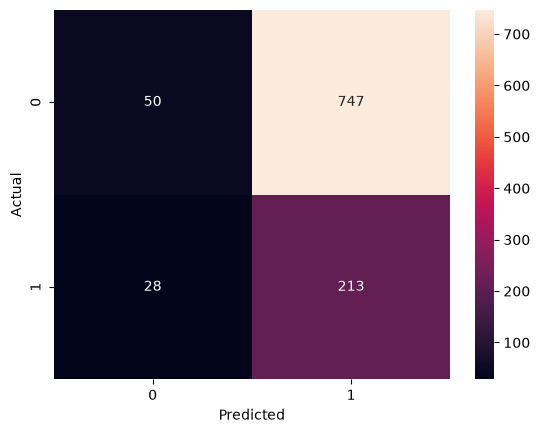

In [ ]:


# confusion matrix
import seaborn as sns
sns.heatmap(confusion_matrix(yte, test_predictions), annot=True, fmt='g')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import average_precision_score, roc_auc_score

# Get predicted probabilities
y_pred_proba = model.predict(Xte).ravel()

# Calculate AUC scores
pr_auc = average_precision_score(yte, y_pred_proba)
roc_auc = roc_auc_score(yte, y_pred_proba)

print(f"PR-AUC:  {pr_auc:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")
y_pred = (y_pred_proba >= threshold).astype(int)

print(confusion_matrix(yte, y_pred))
print(classification_report(yte, y_pred))

acc = accuracy_score(yte, test_predictions)
print("\nModel overall accuracy: {:.2f}%".format(acc * 100))

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 750us/step
PR-AUC:  0.5322
ROC-AUC: 0.6600
[[ 50 747]
 [ 28 213]]
              precision    recall  f1-score   support

           0       0.64      0.06      0.11       797
           1       0.22      0.88      0.35       241

    accuracy                           0.25      1038
   macro avg       0.43      0.47      0.23      1038
weighted avg       0.54      0.25      0.17      1038


Model overall accuracy: 25.34%


In [ ]:
y_prob = model.predict(Xte).ravel()

print(pd.Series(y_prob).describe())

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 719us/step
count    1038.000000
mean        0.733415
std         0.147024
min         0.122235
25%         0.682445
50%         0.751445
75%         0.823908
max         0.998202
dtype: float64


In [ ]:
y_prob = model.predict(Xte).ravel()

print("Actual frost bumps:", np.sum(yte == 1))
print("Predicted frost bumps:", np.sum(y_prob >= threshold))

print("\nProbabilities for actual frost bumps:")
print(y_prob[yte == 1])

 1/33 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 766us/step
Actual frost bumps: 241
Predicted frost bumps: 960

Probabilities for actual frost bumps:
[0.7559216  0.8380586  0.90555316 0.9399307  0.73822284 0.92670906
 0.8981261  0.7923572  0.86679953 0.97782224 0.9494647  0.862962
 0.8756554  0.80502194 0.7269251  0.78793883 0.7695355  0.8949809
 0.88500774 0.81519943 0.8677862  0.8889143  0.7797082  0.9877099
 0.9713493  0.8650495  0.84540343 0.83914244 0.792931   0.6834445
 0.78217566 0.7524333  0.604841   0.7613719  0.85382855 0.8703667
 0.6358532  0.66964775 0.87892413 0.6733019  0.6251489  0.72118753
 0.7520134  0.6149709  0.72451377 0.87126625 0.7277727  0.8427393
 0.86162406 0.884418   0.8537405  0.52649117 0.75263184 0.844059
 0.607003   0.9561159  0.89841485 0.89541465 0.7550963  0.67850685
 0.87862843 0.32107264 0.3574299  0.75484115 0.7689264  0.6489334
 0.41716245 0.28642786 0.20522524 0.3861168  0.8253535  0.9192442
 0.57180846 0.45018768 0.4099251  0.3267082  0.25373992 0.1704418
 0.1513189